In [2]:
print(1+1)

2


In [3]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv('churn_data.csv')

In [5]:
df.head(5)

,Age,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,...,Add_Ons_Used,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Premium_Hike_Trend_%,Policy_Renewal_Streak,CSAT_Score,Churn
0,56,Female,Tier 2,575000.0,2,1,Self-Employed,77,1,17478,...,3,0,0,0,3,135,15.0,2,5,0
1,69,Female,Tier 2,1189000.0,3,1,Salaried,78,1,35993,...,1,1,2,57,3,149,16.7,0,3,1
2,46,Female,Tier 3,2528000.0,4,0,Self-Employed,107,1,22078,...,3,1,0,42,2,142,21.0,2,4,0
3,32,Male,Tier 2,1253000.0,5,0,Self-Employed,24,1,39506,...,2,0,0,0,4,22,19.6,2,4,0
4,60,Female,Tier 1,571000.0,2,1,Salaried,46,3,27680,...,2,0,0,0,2,77,5.9,0,4,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Age                          100000 non-null  int64  
 1   Gender                       100000 non-null  object 
 2   Location                     100000 non-null  object 
 3   Income_INR                   100000 non-null  float64
 4   Family_Members               100000 non-null  int64  
 5   Owns_Car                     100000 non-null  int64  
 6   Occupation                   100000 non-null  object 
 7   Tenure_Months                100000 non-null  int64  
 8   Num_Policies                 100000 non-null  int64  
 9   Policy_Premium               100000 non-null  int64  
 10  Coverage_Type                100000 non-null  object 
 11  Payment_Method               100000 non-null  object 
 12  Auto_Renewal                 100000 non-null  int64  
 13  

1. Executive Business KPIs<br>
Churn Metrics<br>
Overall churn rate<br>
Churn by:<br>
Coverage Type<br>
Tier (Tier 1/2/3)<br>
Occupation<br>
Payment Method<br>
Auto Renew Status<br>

In [7]:
#overall churn rate
total_counts = df['Churn'].value_counts().sum()
total_churn = df['Churn'].sum()
churn_rate = total_churn / total_counts
print(f"Overall churn rate: {churn_rate:.2%}")

Overall churn rate: 16.01%


In [8]:
df.columns

Index(['Age', 'Gender', 'Location', 'Income_INR', 'Family_Members', 'Owns_Car',
       'Occupation', 'Tenure_Months', 'Num_Policies', 'Policy_Premium',
       'Coverage_Type', 'Payment_Method', 'Auto_Renewal', 'Add_Ons_Used',
       'Claim_Frequency', 'Claim_Rejection_Count', 'Settlement_Time_Days',
       'Support_Interactions', 'Days_Since_Last_Interaction',
       'Premium_Hike_Trend_%', 'Policy_Renewal_Streak', 'CSAT_Score', 'Churn'],
      dtype='object')

In [9]:
df['Coverage_Type'].value_counts()

Coverage_Type
Basic            50002
Comprehensive    35160
Premium          14838
Name: count, dtype: int64

In [10]:
#churn by coverage type
coverage_churn = df.groupby('Coverage_Type', as_index=False)['Churn'].sum()
print(coverage_churn)

   Coverage_Type  Churn
0          Basic   7966
1  Comprehensive   5732
2        Premium   2310


In [11]:
print(df['Churn'].sum())
print(df['Churn'].value_counts())

16008
Churn
0    83992
1    16008
Name: count, dtype: int64


In [12]:
df.describe(include='all')

,Age,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,...,Add_Ons_Used,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Premium_Hike_Trend_%,Policy_Renewal_Streak,CSAT_Score,Churn
count,100000.000000,100000,100000,1.000000e+05,100000.000000,100000.00000,100000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
unique,NaN,2,3,NaN,NaN,NaN,3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Male,Tier 2,NaN,NaN,NaN,Salaried,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,59896,50077,NaN,NaN,NaN,49963,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,46.033670,NaN,NaN,1.002534e+06,3.005490,0.60151,NaN,59.952160,1.601370,27486.754610,...,1.499740,0.501750,0.395840,12.595300,1.496030,90.016360,12.472072,2.872290,3.001310,0.160080
std,16.433943,NaN,NaN,9.420367e+05,1.412579,0.48959,NaN,34.432708,0.859856,13019.695548,...,1.117458,0.707575,0.709518,18.512661,1.225961,51.659314,7.213887,2.351786,1.415602,0.366682
min,18.000000,NaN,NaN,2.100000e+04,1.000000,0.00000,NaN,1.000000,1.000000,5000.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,32.000000,NaN,NaN,4.250000e+05,2.000000,0.00000,NaN,30.000000,1.000000,16206.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,45.000000,6.200000,1.000000,2.000000,0.000000
50%,46.000000,NaN,NaN,7.280000e+05,3.000000,1.00000,NaN,60.000000,1.000000,27433.500000,...,2.000000,0.000000,0.000000,0.000000,1.000000,90.000000,12.500000,2.000000,3.000000,0.000000
75%,60.000000,NaN,NaN,1.249000e+06,4.000000,1.00000,NaN,90.000000,2.000000,38734.250000,...,2.000000,1.000000,1.000000,24.000000,2.000000,135.000000,18.700000,5.000000,4.000000,0.000000


In [13]:
df.head()

,Age,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,...,Add_Ons_Used,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Premium_Hike_Trend_%,Policy_Renewal_Streak,CSAT_Score,Churn
0,56,Female,Tier 2,575000.0,2,1,Self-Employed,77,1,17478,...,3,0,0,0,3,135,15.0,2,5,0
1,69,Female,Tier 2,1189000.0,3,1,Salaried,78,1,35993,...,1,1,2,57,3,149,16.7,0,3,1
2,46,Female,Tier 3,2528000.0,4,0,Self-Employed,107,1,22078,...,3,1,0,42,2,142,21.0,2,4,0
3,32,Male,Tier 2,1253000.0,5,0,Self-Employed,24,1,39506,...,2,0,0,0,4,22,19.6,2,4,0
4,60,Female,Tier 1,571000.0,2,1,Salaried,46,3,27680,...,2,0,0,0,2,77,5.9,0,4,0


In [14]:
#churn by tier
tier_churn = df.groupby('Location', as_index=False)['Churn'].sum()
print(tier_churn)

  Location  Churn
0   Tier 1   4810
1   Tier 2   7981
2   Tier 3   3217


In [15]:
#churn by occupation
occupation_churn = df.groupby('Occupation')['Churn'].sum()
print(occupation_churn)

Occupation
Business         3170
Salaried         8012
Self-Employed    4826
Name: Churn, dtype: int64


In [16]:
#churn by Auto renewal
churn_by_auto_renewal = df.groupby('Auto_Renewal')['Churn'].sum()
print(churn_by_auto_renewal)

Auto_Renewal
0    7485
1    8523
Name: Churn, dtype: int64


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='Coverage_Type', ylabel='Churn'>

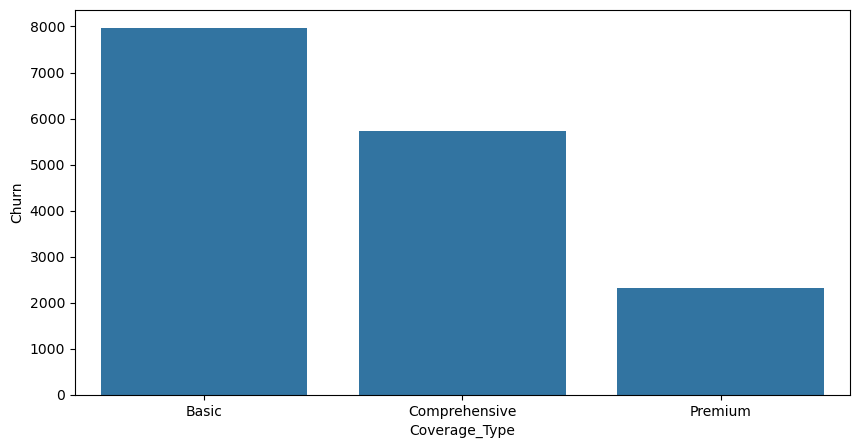

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Coverage_Type', y='Churn', data=coverage_churn)

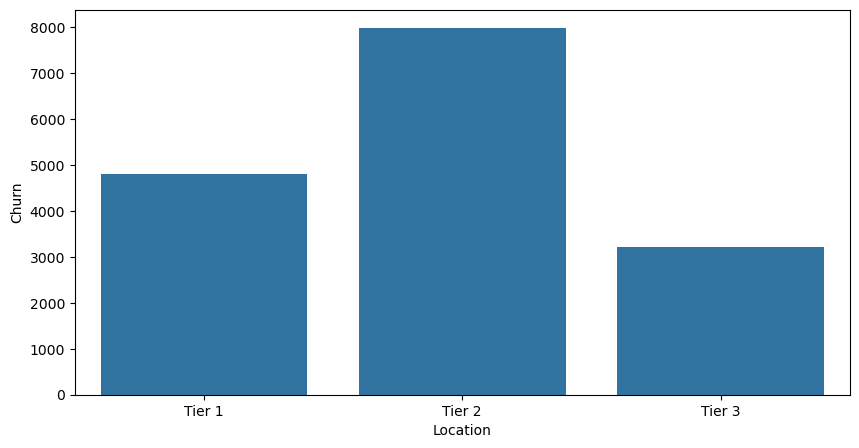

In [19]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Location', y='Churn', data=tier_churn)
plt.show()

2. Customer Demographic Analysis<br>
Age Analysis<br>
Age distribution<br>
Age vs Churn<br>
Age band analysis

In [20]:
df.tail()

,Age,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,...,Add_Ons_Used,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Premium_Hike_Trend_%,Policy_Renewal_Streak,CSAT_Score,Churn
99995,67,Female,Tier 2,1688000.0,5,0,Self-Employed,84,2,20346,...,1,1,1,31,1,22,1.8,4,5,0
99996,58,Female,Tier 3,325000.0,2,0,Salaried,57,1,21613,...,3,0,0,0,1,139,5.3,4,1,0
99997,45,Male,Tier 1,295000.0,5,1,Self-Employed,84,3,45527,...,0,1,0,25,1,175,17.3,0,3,0
99998,18,Male,Tier 2,1987000.0,2,0,Business,64,4,32348,...,2,0,0,0,0,121,21.2,5,5,0
99999,19,Female,Tier 3,2861000.0,4,0,Salaried,115,3,45478,...,2,1,2,30,0,88,22.6,6,3,0


In [21]:
print(df['Age'].min())
print(df['Age'].max())

18
74


In [22]:
bin = [18, 30, 40, 50, 60, 70, 80]
df['Age_Group'] = pd.cut(df['Age'], bins=bin)
df['Age_Group'].value_counts()

Age_Group
(18, 30]    20894
(30, 40]    17814
(40, 50]    17528
(60, 70]    17517
(50, 60]    17407
(70, 80]     7155
Name: count, dtype: int64

In [23]:
#Age group churn
age_group_churn = df.groupby('Age_Group', as_index=False)['Churn'].sum()
print(age_group_churn)

  Age_Group  Churn
0  (18, 30]   3404
1  (30, 40]   2888
2  (40, 50]   2693
3  (50, 60]   2770
4  (60, 70]   2804
5  (70, 80]   1198


C:\Users\lenovo\AppData\Local\Temp\ipykernel_13132\1376741863.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_churn = df.groupby('Age_Group', as_index=False)['Churn'].sum()


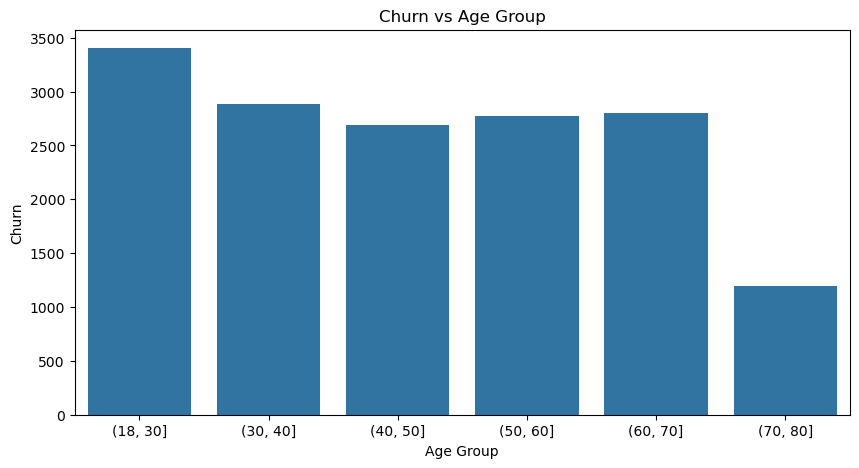

In [24]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Age_Group', y='Churn', data=age_group_churn)
plt.title('Churn vs Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn')
plt.show()

In [25]:
print(df['Premium_Hike_Trend_%'].max())
print(df['Premium_Hike_Trend_%'].min())

25.0
0.0


In [26]:
bin2 = [0, 5, 10, 15, 20, 25]
df['Premium_Hike_Trend_Group'] = pd.cut(df['Premium_Hike_Trend_%'], bins=bin2)
df['Premium_Hike_Trend_Group'].value_counts()

Premium_Hike_Trend_Group
(5, 10]     20156
(0, 5]      20072
(15, 20]    19969
(10, 15]    19863
(20, 25]    19721
Name: count, dtype: int64

In [27]:
df = df.drop(columns=['Age', 'Premium_Hike_Trend_%'])

In [28]:
#premium hike trend group churn
premium_hike_trend_churn = df.groupby('Premium_Hike_Trend_Group', as_index=False)['Churn'].sum()
print(premium_hike_trend_churn)

  Premium_Hike_Trend_Group  Churn
0                   (0, 5]   2134
1                  (5, 10]   2721
2                 (10, 15]   3224
3                 (15, 20]   3669
4                 (20, 25]   4240


C:\Users\lenovo\AppData\Local\Temp\ipykernel_13132\973855058.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  premium_hike_trend_churn = df.groupby('Premium_Hike_Trend_Group', as_index=False)['Churn'].sum()


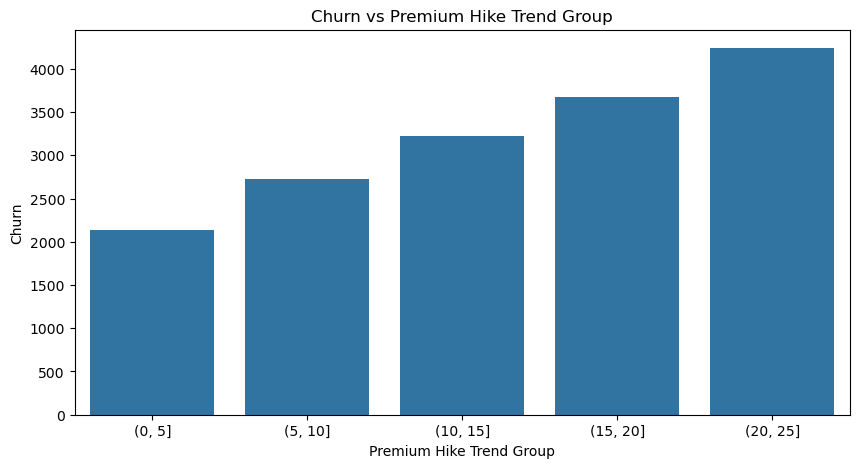

In [29]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Premium_Hike_Trend_Group', y='Churn', data=premium_hike_trend_churn)
plt.title('Churn vs Premium Hike Trend Group')
plt.xlabel('Premium Hike Trend Group')
plt.ylabel('Churn')
plt.show()

In [30]:
df.head()

,Gender,Location,Income_INR,Family_Members,Owns_Car,Occupation,Tenure_Months,Num_Policies,Policy_Premium,Coverage_Type,...,Claim_Frequency,Claim_Rejection_Count,Settlement_Time_Days,Support_Interactions,Days_Since_Last_Interaction,Policy_Renewal_Streak,CSAT_Score,Churn,Age_Group,Premium_Hike_Trend_Group
0,Female,Tier 2,575000.0,2,1,Self-Employed,77,1,17478,Premium,...,0,0,0,3,135,2,5,0,"(50, 60]","(10, 15]"
1,Female,Tier 2,1189000.0,3,1,Salaried,78,1,35993,Comprehensive,...,1,2,57,3,149,0,3,1,"(60, 70]","(15, 20]"
2,Female,Tier 3,2528000.0,4,0,Self-Employed,107,1,22078,Basic,...,1,0,42,2,142,2,4,0,"(40, 50]","(20, 25]"
3,Male,Tier 2,1253000.0,5,0,Self-Employed,24,1,39506,Premium,...,0,0,0,4,22,2,4,0,"(30, 40]","(15, 20]"
4,Female,Tier 1,571000.0,2,1,Salaried,46,3,27680,Comprehensive,...,0,0,0,2,77,0,4,0,"(50, 60]","(5, 10]"


### Identify Null Values

In [37]:
df.isnull().sum()

Gender                            0
Location                          0
Income_INR                        0
Family_Members                    0
Owns_Car                          0
Occupation                        0
Tenure_Months                     0
Num_Policies                      0
Policy_Premium                    0
Coverage_Type                     0
Payment_Method                    0
Auto_Renewal                      0
Add_Ons_Used                      0
Claim_Frequency                   0
Claim_Rejection_Count             0
Settlement_Time_Days              0
Support_Interactions              0
Days_Since_Last_Interaction       0
Policy_Renewal_Streak             0
CSAT_Score                        0
Churn                             0
Age_Group                      1685
Premium_Hike_Trend_Group        219
dtype: int64

In [38]:
df.shape

(100000, 23)

In [40]:
(1685+219)/100000

0.01904

In [41]:
df=df.dropna()

In [42]:
df.shape

(98100, 23)

### Identify Outliers

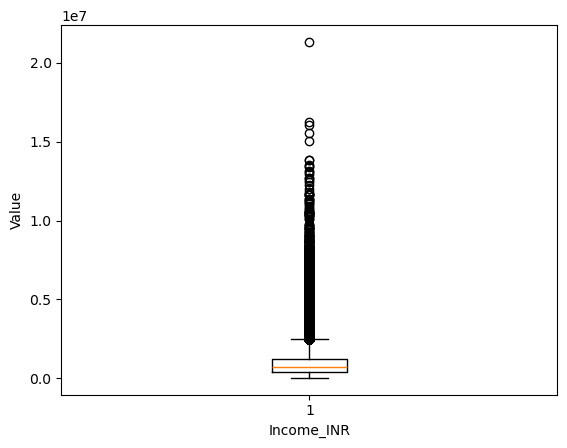

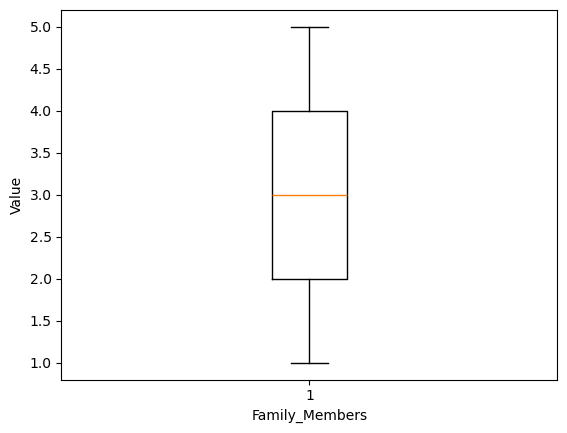

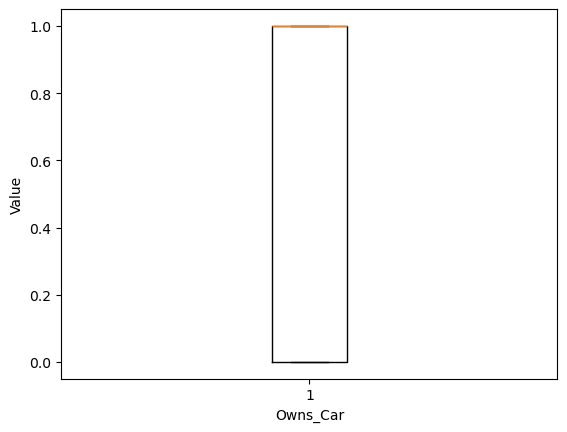

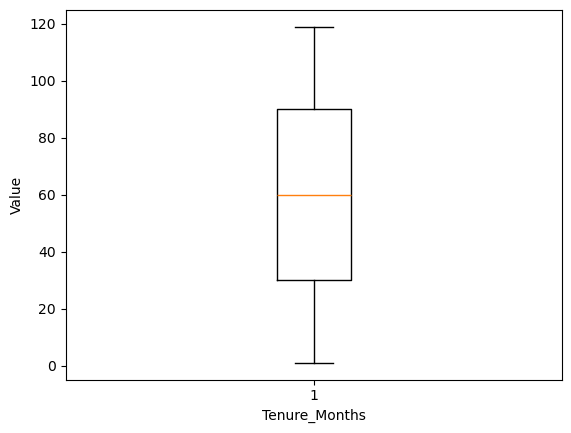

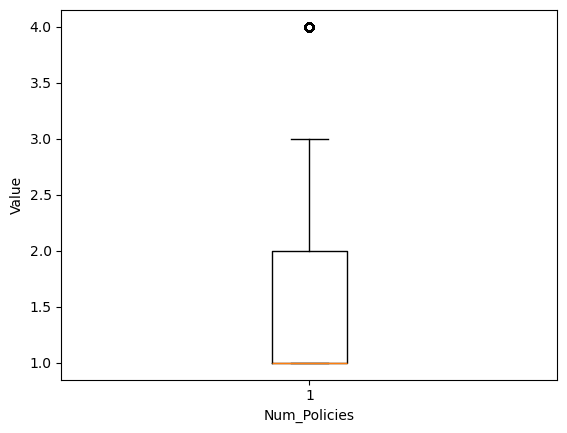

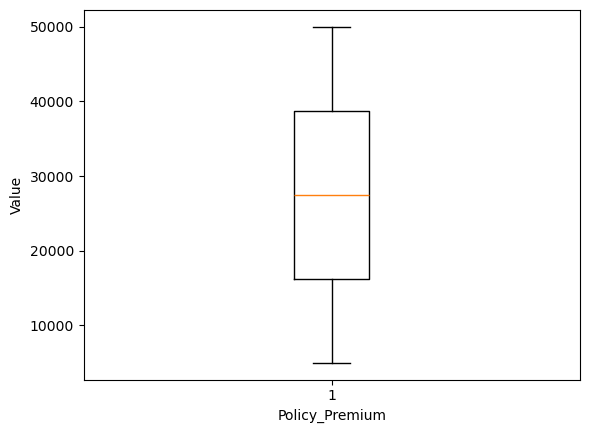

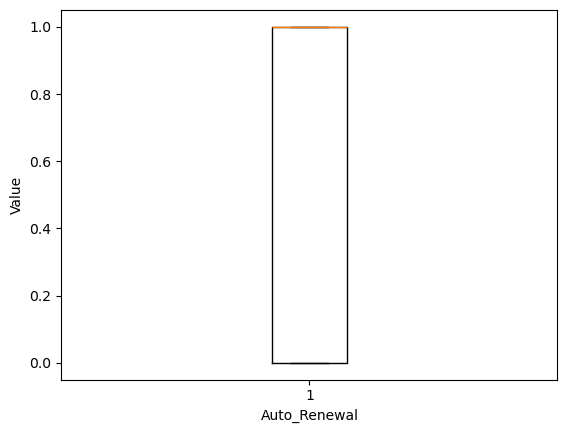

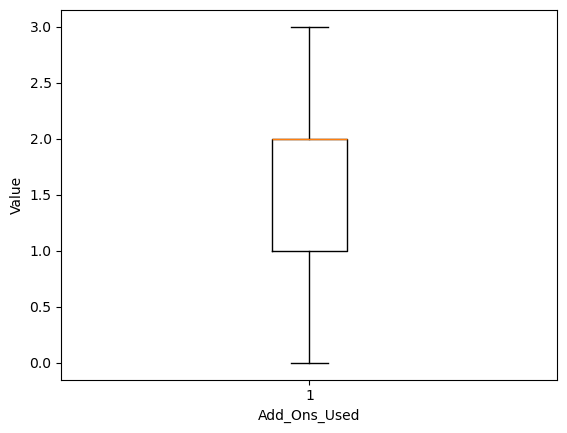

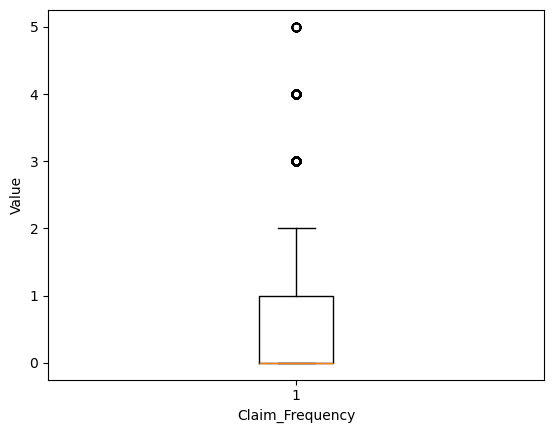

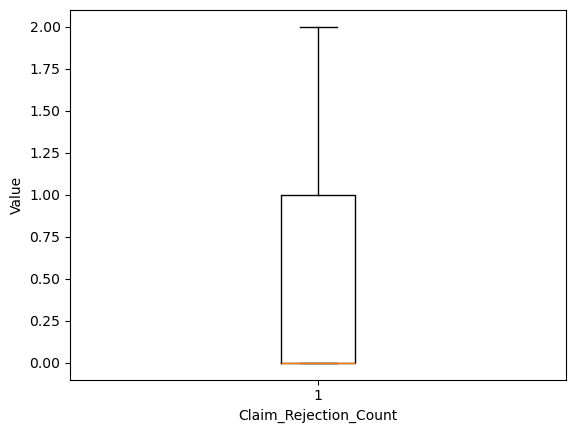

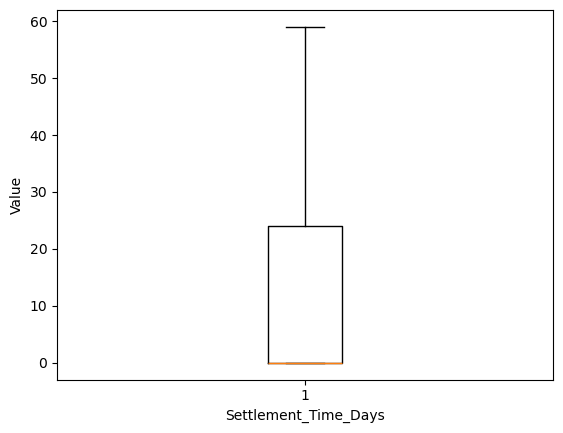

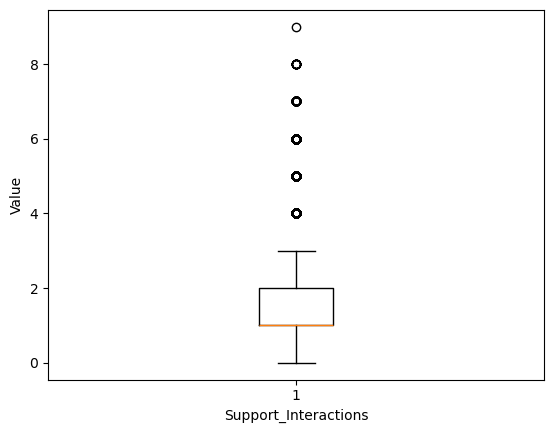

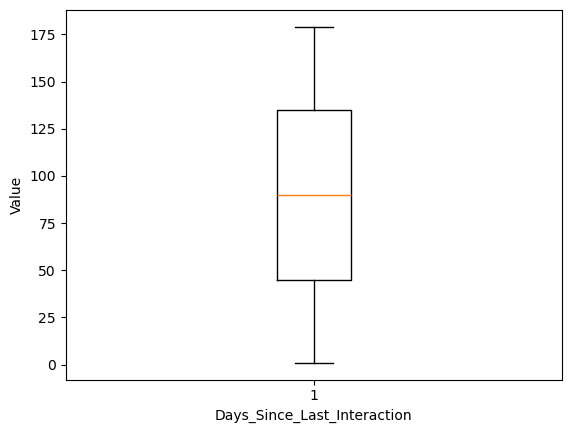

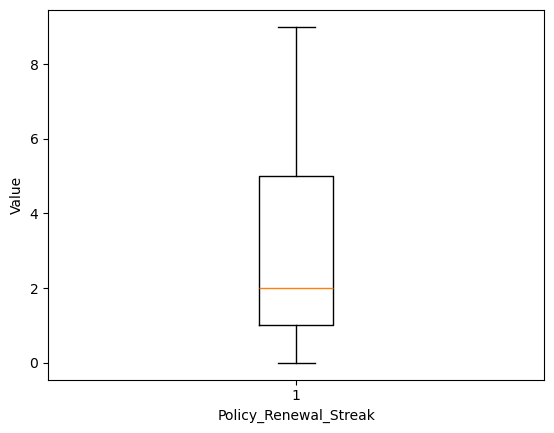

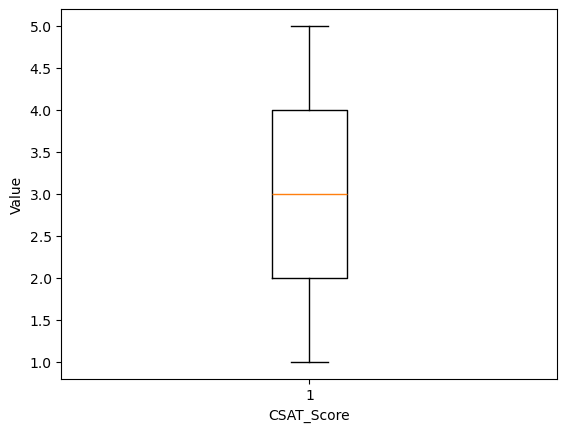

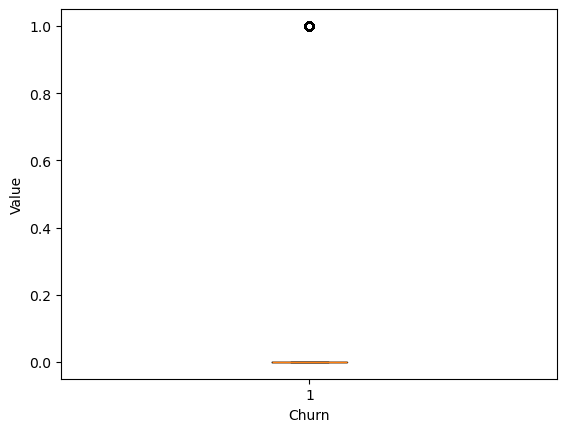

In [46]:
for col in df.select_dtypes(include="number").columns:
    values = df[col].dropna()
    if not values.empty:
        plt.figure()
        plt.boxplot(values)
        plt.xlabel(col)
        plt.ylabel("Value")
        plt.show()

In [47]:
df.columns

Index(['Gender', 'Location', 'Income_INR', 'Family_Members', 'Owns_Car',
       'Occupation', 'Tenure_Months', 'Num_Policies', 'Policy_Premium',
       'Coverage_Type', 'Payment_Method', 'Auto_Renewal', 'Add_Ons_Used',
       'Claim_Frequency', 'Claim_Rejection_Count', 'Settlement_Time_Days',
       'Support_Interactions', 'Days_Since_Last_Interaction',
       'Policy_Renewal_Streak', 'CSAT_Score', 'Churn', 'Age_Group',
       'Premium_Hike_Trend_Group'],
      dtype='object')

In [48]:
Ins = ['Income_INR', 'Claim_Frequency', 'Support_Interactions']
for col in Ins:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    LW = Q1 - 1.5 * IQR
    UW = Q3 + 1.5 * IQR
    df = df[(df[col] >= LW) & (df[col] <= UW)]

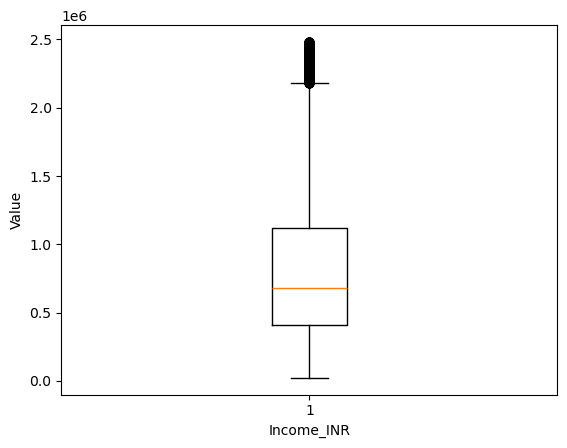

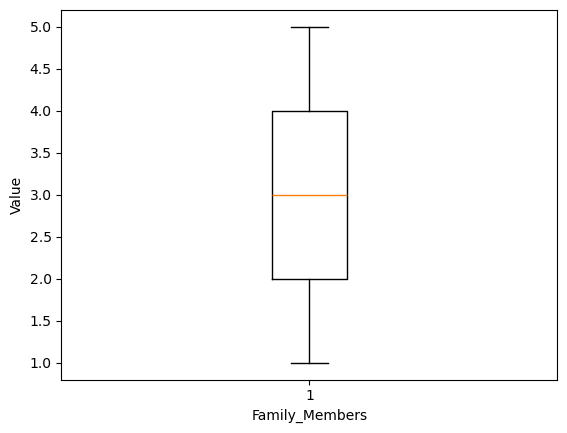

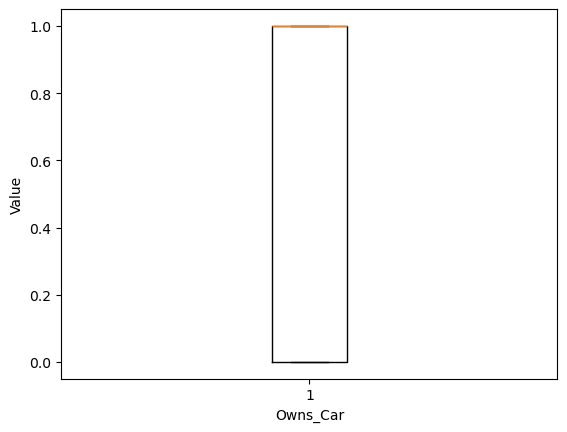

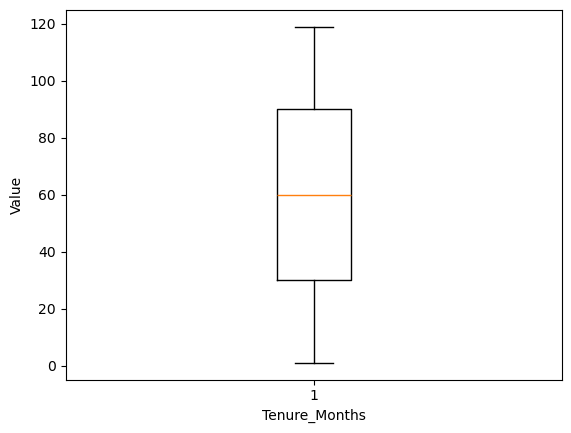

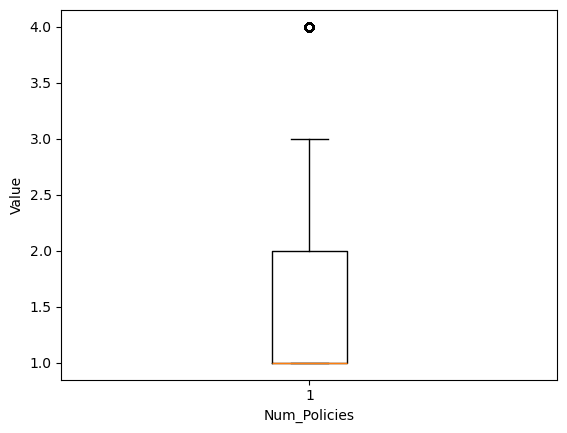

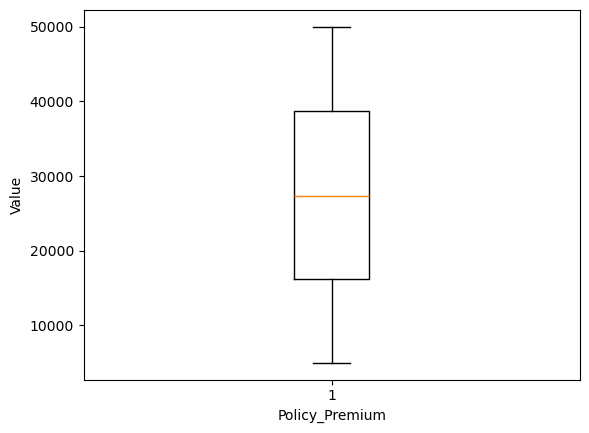

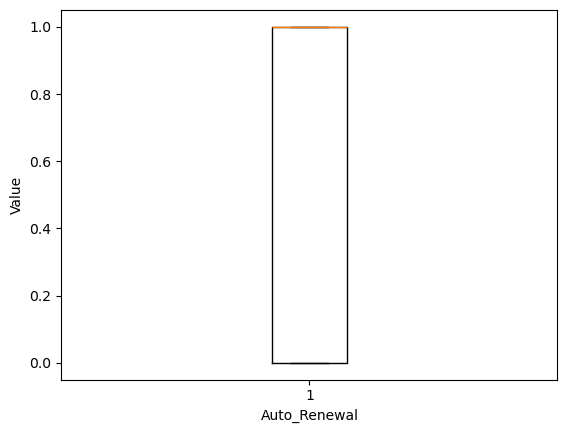

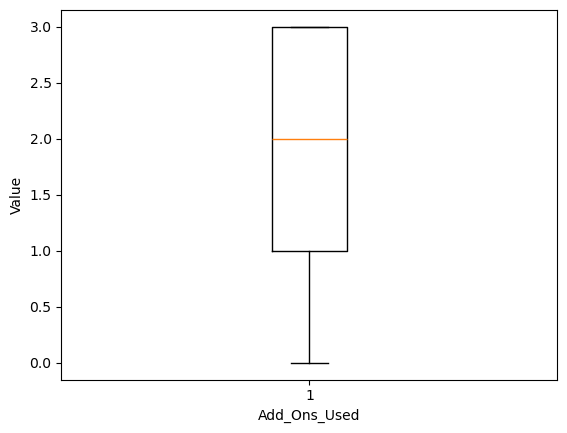

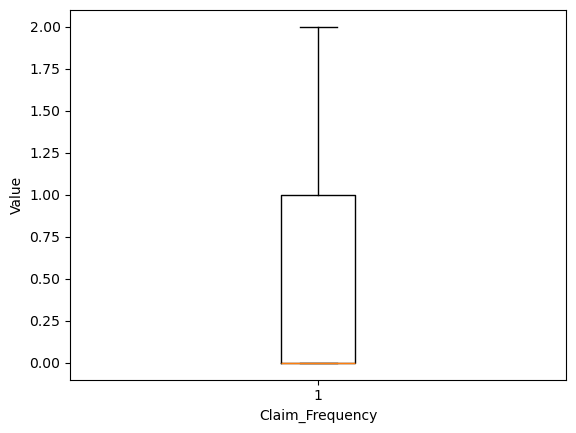

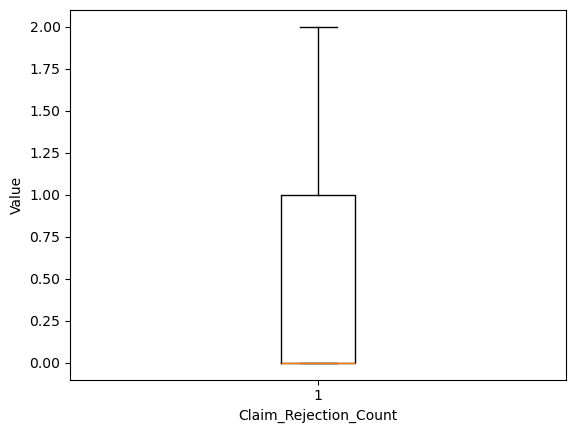

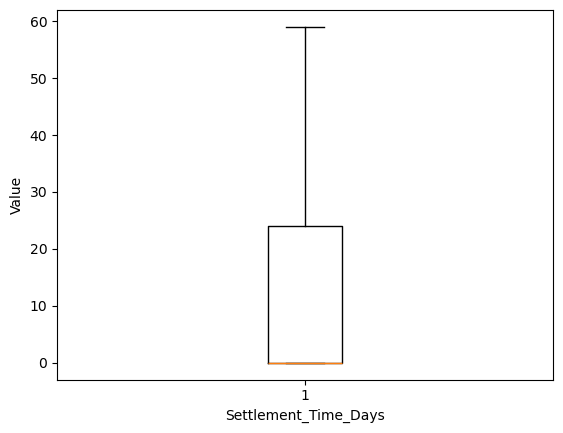

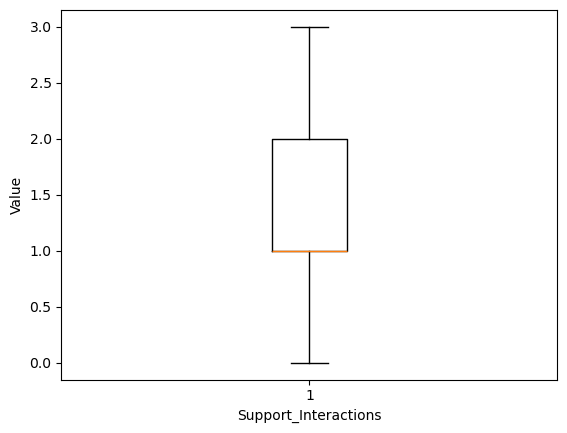

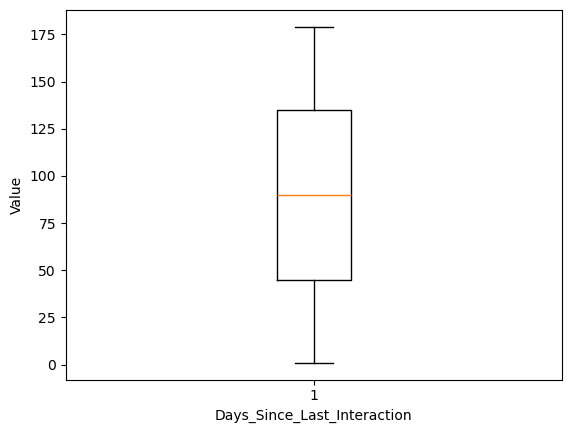

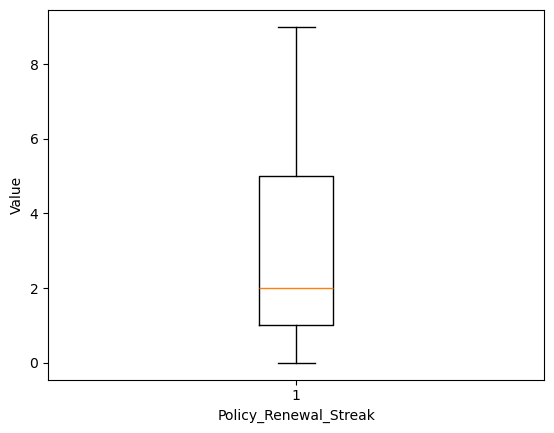

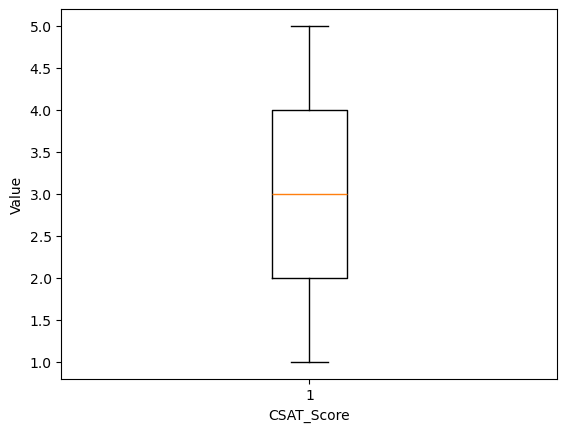

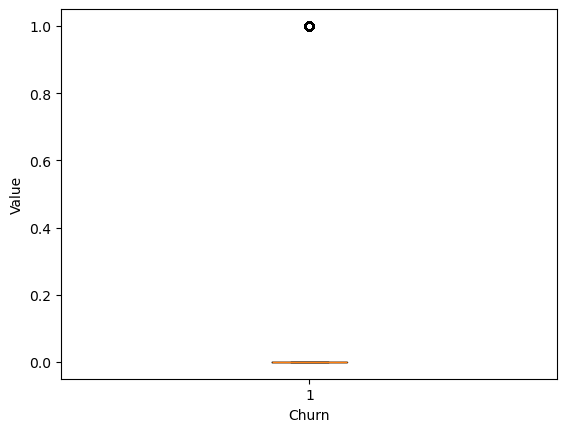

In [49]:
for col in df.select_dtypes(include="number").columns:
    values = df[col].dropna()
    if not values.empty:
        plt.figure()
        plt.boxplot(values)
        plt.xlabel(col)
        plt.ylabel("Value")
        plt.show()

In [50]:
df.shape

(84729, 23)